# Klasifikasi Inflasi Kabupaten/Kota Sumatera Utara (2024 - 2026)

**Tujuan:** memprediksi apakah inflasi bulanan suatu wilayah bernilai positif, dengan membandingkan KNN, Naive Bayes, Decision Tree, dan SVM menggunakan 5-fold cross-validation.

**Sumber data:** Perkembangan Inflasi 8 Kabupaten/Kota IHK di Provinsi Sumatera Utara (2022=100), BPS Sumatera Utara, tahun 2024, 2025, dan 2026 (Januari sampai September).


## Alur Notebook

1. **Judul dan tujuan:** memprediksi apakah inflasi bulanan suatu wilayah bernilai positif.
2. **Kode utama:** membaca ketiga berkas CSV BPS, membuat fitur `lag1`, membuat target `label`, lalu membandingkan KNN, Naive Bayes, Decision Tree, dan SVM dengan 5-fold cross-validation. Hasilnya berupa tabel dan confusion matrix Decision Tree.
3. **Catatan fitur:** target, fitur yang dipakai, dan alasan inflasi bulan yang sama tidak dijadikan fitur.
4. **Hasil:** tabel akurasi dan F1-macro untuk setiap model.
5. **Baseline dan interpretasi:** pembanding tebakan mayoritas dan aturan keputusan Decision Tree.
6. **Pembahasan:** akurasi yang menyesatkan, kelemahan pada kelas minoritas, selisih antar model, dan keterbatasan penelitian.

Baris mentah (tanpa provinsi): 264
Jumlah baris setelah fitur lag: 256
label
Positif          163
Tidak positif     93
Name: count, dtype: int64
                  Model  Akurasi (mean)  Akurasi (std)  F1-macro (mean)  F1-macro (std)
Decision Tree (depth=4)           0.660          0.027            0.550           0.069
 Naive Bayes (Gaussian)           0.558          0.072            0.490           0.062
              KNN (k=5)           0.605          0.035            0.490           0.039
              SVM (RBF)           0.645          0.013            0.437           0.026


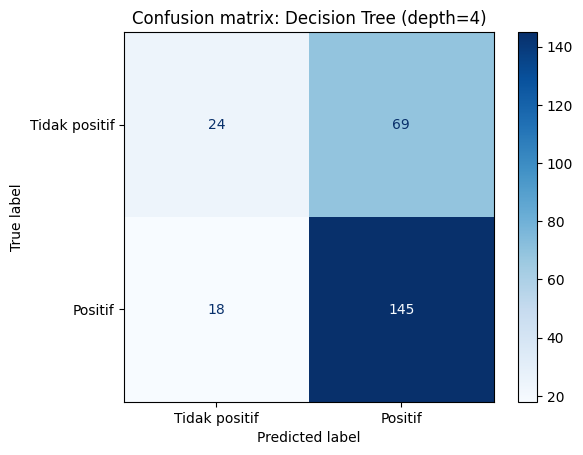

In [8]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay

paths = [
    "/Perkembangan Inflasi 8 Kabupaten_Kota IHK di Provinsi Sumatera Utara (2022=100), 2024.csv",
    "/Perkembangan Inflasi 8 Kabupaten_Kota IHK di Provinsi Sumatera Utara (2022=100), 2025.csv",
    "/Perkembangan Inflasi 8 Kabupaten_Kota IHK di Provinsi Sumatera Utara (2022=100), 2026.csv",
]
BULAN = ['Januari','Februari','Maret','April','Mei','Juni','Juli',
         'Agustus','September','Oktober','November','Desember']

def baca_file(path):
    raw = pd.read_csv(path, header=None, encoding='utf-8-sig', dtype=str)
    tahun = int(next(str(v).strip() for v in raw.iloc[:, 1]
                     if re.fullmatch(r'\d{4}', str(v).strip())))
    hdr = raw.index[raw.iloc[:, 1].eq('Januari')][0]
    rows = []
    for _, r in raw.iloc[hdr + 1:].iterrows():
        wilayah = str(r[0]).strip()
        if wilayah in ('', 'nan', 'Sumatera Utara'):
            continue
        for j, _b in enumerate(BULAN, start=1):
            v = str(r[j]).strip()
            if v in ('-', 'nan', ''):
                continue
            rows.append({'wilayah': wilayah, 'tahun': tahun,
                         'bulan': j, 'inflasi': float(v)})
    return pd.DataFrame(rows)

df = pd.concat([baca_file(p) for p in paths], ignore_index=True)
print('Baris mentah (tanpa provinsi):', len(df))

df = df.sort_values(['wilayah', 'tahun', 'bulan']).reset_index(drop=True)
df['lag1'] = df.groupby('wilayah')['inflasi'].shift(1)
df = df.dropna(subset=['lag1']).reset_index(drop=True)
df['label'] = (df['inflasi'] > 0).astype(int)

X = df[['wilayah', 'bulan', 'lag1']]
y = df['label']
print('Jumlah baris setelah fitur lag:', len(df))
print(y.value_counts().rename({0: 'Tidak positif', 1: 'Positif'}))

prep = ColumnTransformer(
    [('wil', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['wilayah']),
     ('num', StandardScaler(), ['bulan', 'lag1'])])

models = {
    'KNN (k=5)':                  make_pipeline(prep, KNeighborsClassifier(n_neighbors=5)),
    'Naive Bayes (Gaussian)':     make_pipeline(prep, GaussianNB()),
    'Decision Tree (depth=4)':    make_pipeline(prep, DecisionTreeClassifier(max_depth=4, random_state=42)),
    'SVM (RBF)':                  make_pipeline(prep, SVC(kernel='rbf', C=1.0)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for nama, model in models.items():
    s = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'f1_macro'])
    rows.append({
        'Model': nama,
        'Akurasi (mean)': s['test_accuracy'].mean(),
        'Akurasi (std)':  s['test_accuracy'].std(),
        'F1-macro (mean)': s['test_f1_macro'].mean(),
        'F1-macro (std)':  s['test_f1_macro'].std(),
    })
hasil = pd.DataFrame(rows).sort_values('F1-macro (mean)', ascending=False)
print(hasil.round(3).to_string(index=False))

terbaik = hasil.iloc[0]['Model']
y_pred = cross_val_predict(models[terbaik], X, y, cv=cv)
ConfusionMatrixDisplay.from_predictions(
    y, y_pred, display_labels=['Tidak positif', 'Positif'], cmap='Blues')
plt.title(f'Confusion matrix: {terbaik}')
plt.savefig('confusion_matrix_terbaik.png', dpi=150)
plt.show()

Visualisasi Deret Waktu
Grafik ini menunjukkan inflasi bulanan per wilayah sebelum pembuatan fitur lag

In [ ]:
data_mentah = pd.concat([baca_file(p) for p in paths], ignore_index=True)
data_mentah['t'] = data_mentah['tahun'] + (data_mentah['bulan'] - 1) / 12

fig, ax = plt.subplots(figsize=(8, 4))
for wilayah, g in data_mentah.groupby('wilayah'):
    ax.plot(g['t'], g['inflasi'], lw=1, label=wilayah)
ax.axhline(0, color='k', lw=0.7, ls='--')
ax.set_xlabel('Tahun')
ax.set_ylabel('Inflasi bulanan (%)')
ax.set_title('Inflasi bulanan per kabupaten/kota, Jan 2024 - Sep 2026')
ax.legend(fontsize=7, ncol=2, frameon=False)
plt.tight_layout()
plt.savefig('deret_waktu.png', dpi=200)
plt.show()


## Catatan fitur
- Target: `label = 1` jika inflasi bulan tersebut > 0.
- Fitur: wilayah (one-hot), bulan, dan inflasi bulan sebelumnya (`lag1`).
- Inflasi bulan yang sama tidak dipakai sebagai fitur, karena itu sama dengan target.

## Hasil

Tabel berikut merangkum 5-fold cross-validation (rata-rata ± standar deviasi) pada 256 baris data.

| Model | Akurasi | F1-macro |
|---|---|---|
| Decision Tree (depth=4) | 0,660 ± 0,027 | **0,550 ± 0,069** |
| KNN (k=5) | 0,605 ± 0,035 | 0,490 ± 0,039 |
| Naive Bayes (Gaussian) | 0,558 ± 0,072 | 0,490 ± 0,062 |
| SVM (RBF) | 0,645 ± 0,013 | 0,437 ± 0,026 |
| Baseline (kelas mayoritas) | 0,637 | 0,389 |

Decision Tree memiliki F1-macro tertinggi. Confusion matrix Decision Tree (agregat dari 5 fold) menunjukkan 24 dari 93 kasus "tidak positif" terdeteksi dengan benar, dan 145 dari 163 kasus "positif" terdeteksi dengan benar.


## Baseline dan interpretasi model
Sel ini membandingkan Decision Tree dengan tebakan mayoritas, dan menampilkan aturan keputusan.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import export_text

# Baseline: selalu menebak kelas mayoritas
baseline = make_pipeline(prep, DummyClassifier(strategy='most_frequent'))
sb = cross_validate(baseline, X, y, cv=cv, scoring=['accuracy', 'f1_macro'])
print('Baseline (mayoritas) Akurasi: %.3f | F1-macro: %.3f' % (
    sb['test_accuracy'].mean(), sb['test_f1_macro'].mean()))

# Aturan Decision Tree yang dilatih pada seluruh data (untuk interpretasi)
dt = make_pipeline(prep, DecisionTreeClassifier(max_depth=4, random_state=42)).fit(X, y)
nama_fitur = list(dt.named_steps['columntransformer'].get_feature_names_out())
print(export_text(dt.named_steps['decisiontreeclassifier'], feature_names=nama_fitur))


## Pembahasan

**1. Akurasi saja menyesatkan.** Akurasi Decision Tree (0,660) hanya sedikit di atas baseline yang selalu menebak kelas mayoritas (0,637). Namun F1-macro-nya (0,550) jauh di atas baseline (0,389). Ini menunjukkan bahwa model sudah belajar mengenali kelas minoritas, meskipun masih lemah.

**2. Kelas minoritas sulit dikenali.** Recall untuk kelas "tidak positif" hanya sekitar 26%. Sebagian besar kesalahan berupa prediksi "positif" untuk kasus yang sebenarnya tidak positif (69 kasus).

**3. Selisih antar model belum tentu bermakna.** Selisih F1-macro Decision Tree dengan KNN dan Naive Bayes (0,060) kira-kira sama dengan standar deviasi masing-masing model. Dengan 5 fold dan data sekecil ini, peringkat antar model perlu dibaca dengan hati-hati.

**4. Aturan yang dipelajari.** Decision Tree terutama memakai inflasi bulan sebelumnya (`lag1`), bulan, dan wilayah Kota Gunungsitoli. Pola ini masuk akal: inflasi cenderung berkelanjutan dari satu bulan ke bulan berikutnya. Tetapi karena fitur sudah distandarisasi, aturan di atas perlu diterjemahkan kembali ke skala asli sebelum dijelaskan di laporan.

**5. Keterbatasan.**
- Validasi K-fold acak memungkinkan bulan yang berdekatan berada di data latih dan data uji sekaligus, sehingga hasilnya bisa optimistis.
- Fitur terbatas. Tidak ada indikator ekonomi lain seperti harga komoditas atau kurs.
- Data 2026 hanya sampai September dan ada outlier, misalnya Kota Gunungsitoli Desember 2025 sebesar 6,94%.
- Kelas tidak seimbang (163 vs 93).

**Kesimpulan** Dengan fitur sederhana, model klasifikasi belum mampu memprediksi arah inflasi dengan andal, tetapi Decision Tree memberikan peningkatan yang berarti dibanding baseline dalam mengenali kelas minoritas. Peningkatan ini perlu diuji dengan `TimeSeriesSplit` sebelum disimpulkan lebih jauh.
